Mounted at /content/drive
Best model exists: True
Device: cuda

Extracting IP102 dataset...
Dataset extraction completed.
Test images: 22619

Model loaded successfully.
Best epoch: 8
Validation Macro-F1: 0.6221625840685715


E1 Test:   0%|          | 0/707 [00:00<?, ?it/s]


E1 RESNET50 TEST RESULTS
Test Accuracy:        0.7111
Test Macro Precision: 0.6624
Test Macro Recall:    0.6175
Test Macro-F1:        0.6271

Classification report saved.


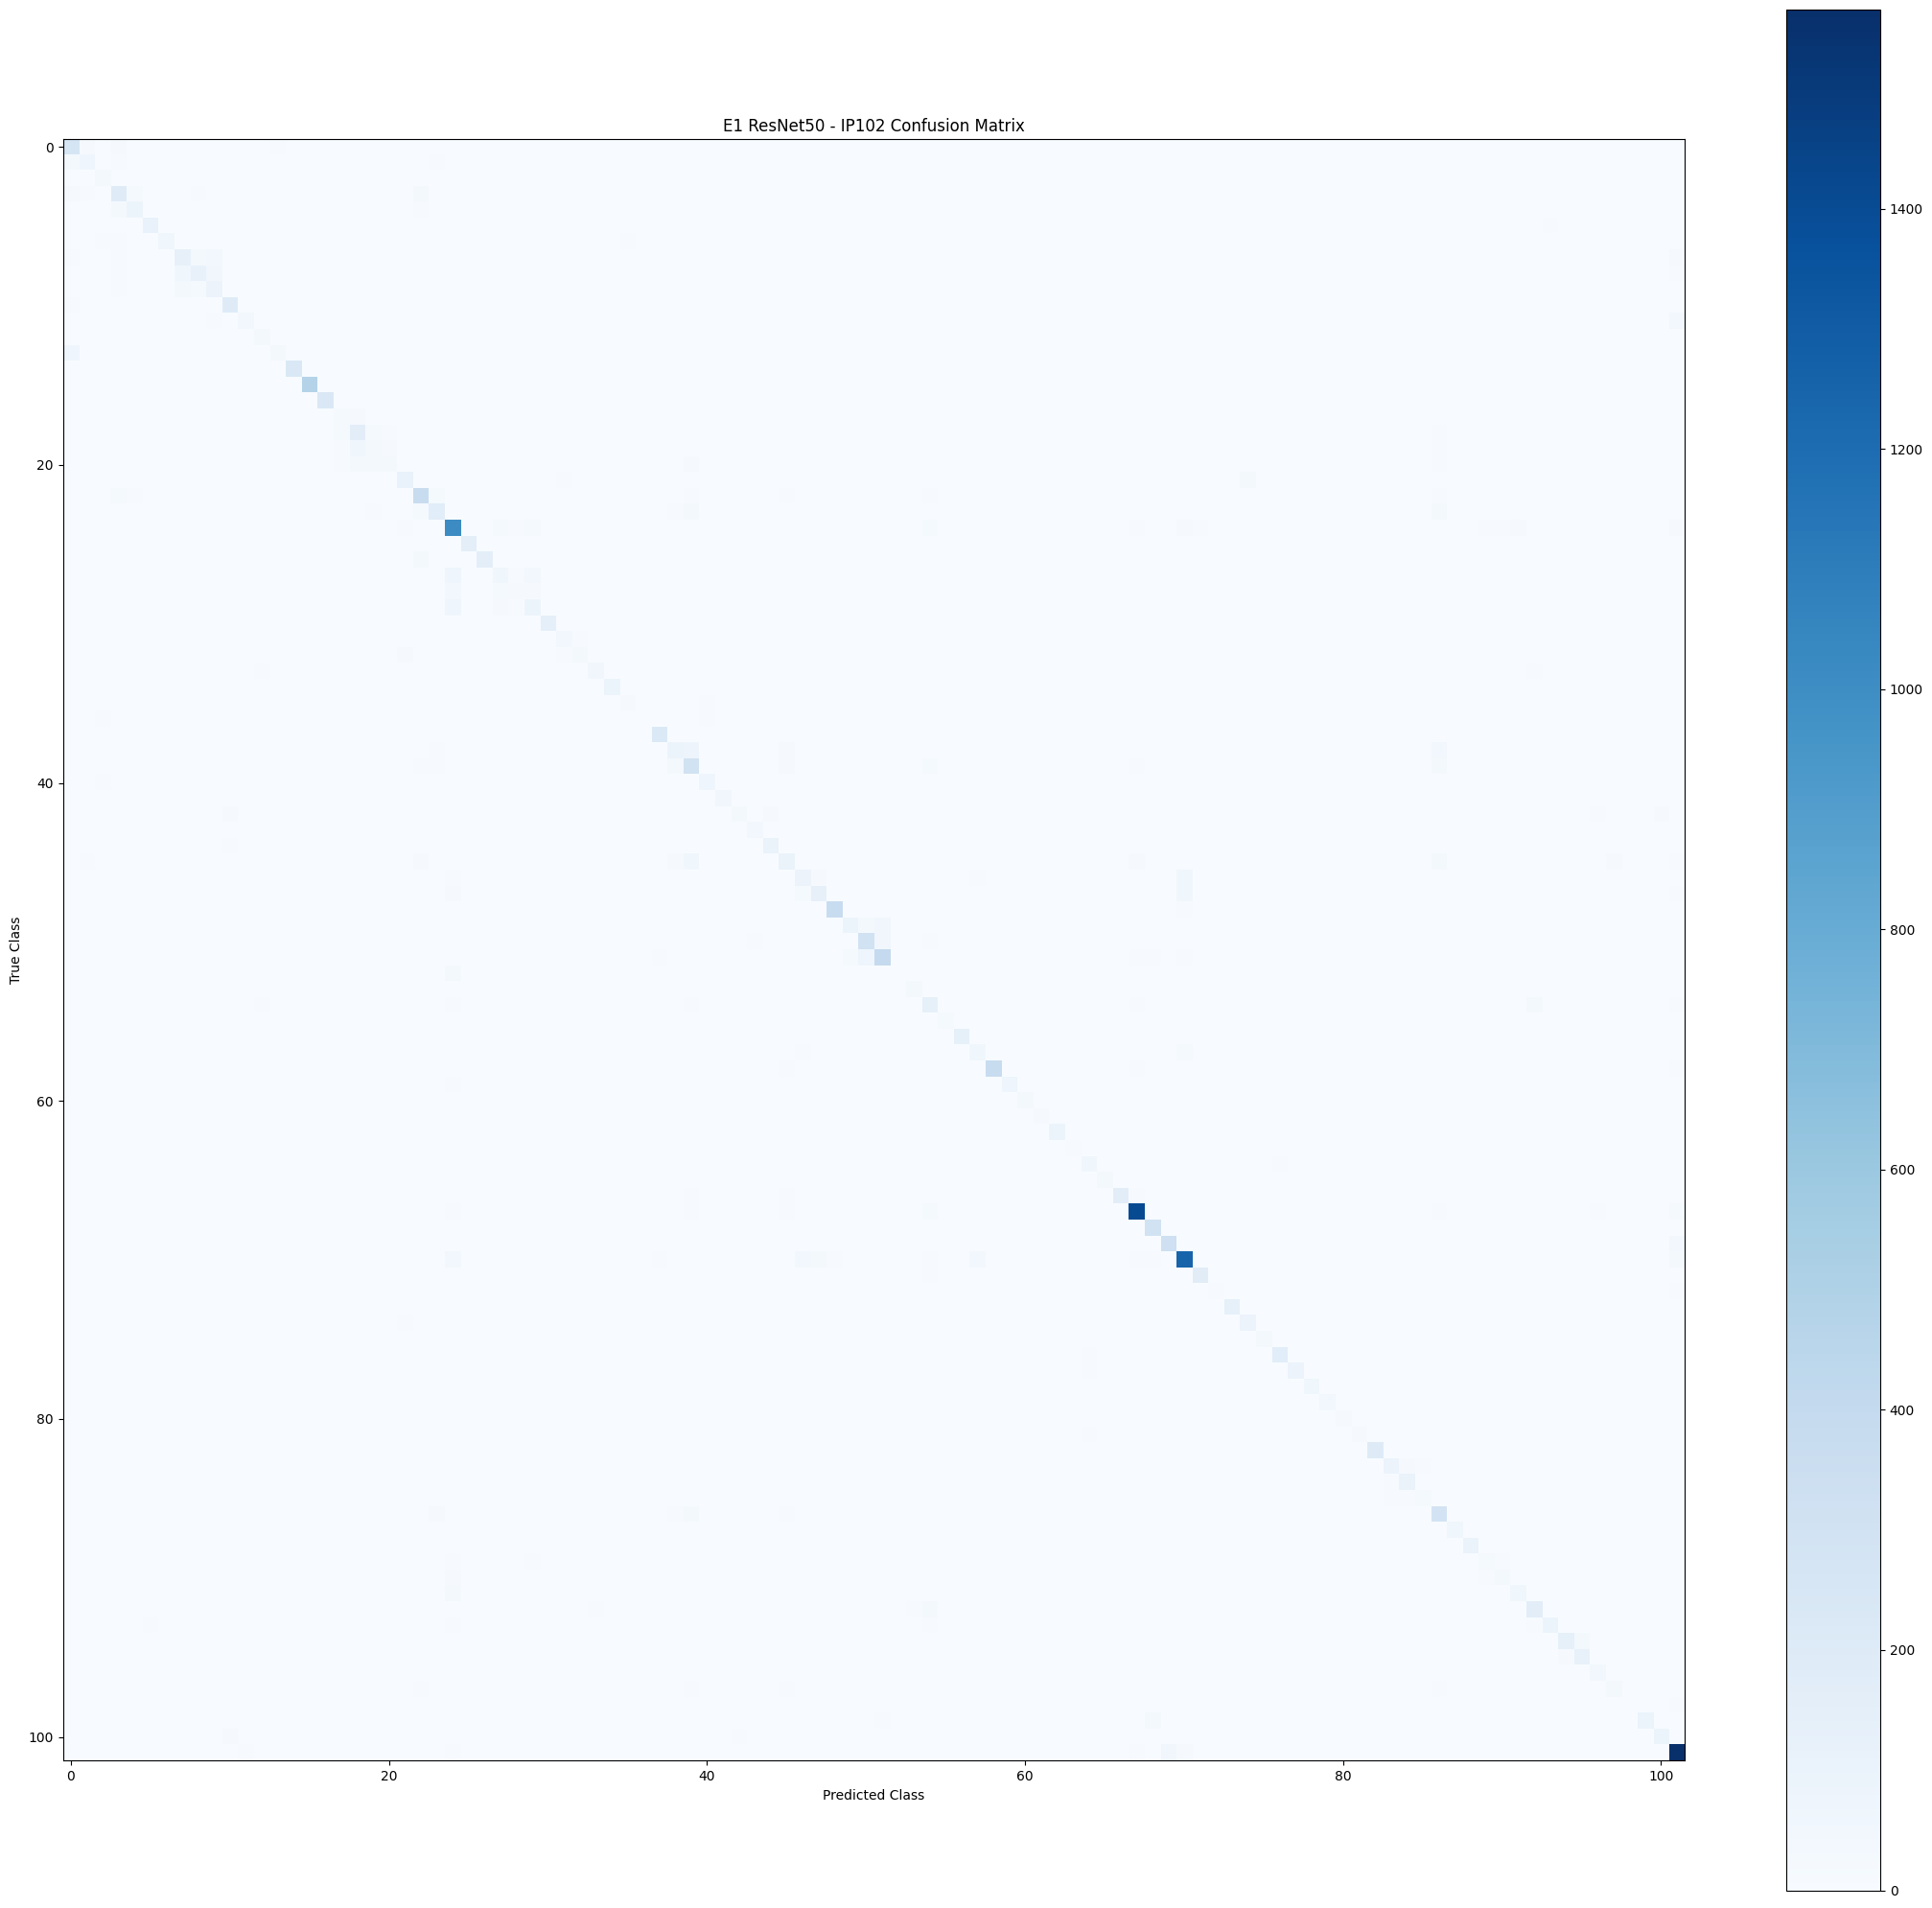


E1 TEST COMPLETED
Best epoch: 8
Test Accuracy: 0.7111
Test Macro-F1: 0.6271

Results saved to:
/content/drive/MyDrive/IP102_Proje/results/E1/test_results


In [1]:
# ============================================================
# E1 - RESNET50 TEST EVALUATION
# IP102 - 102 CLASSES
# ============================================================

import os
import tarfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.models import ResNet50_Weights

from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from google.colab import drive


# ============================================================
# 1. GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/IP102_Proje"
)

DATASET_DIR = PROJECT_DIR / "dataset"

E1_DIR = PROJECT_DIR / "results/E1"

BEST_MODEL_PATH = E1_DIR / "best_model.pth"

TEST_RESULTS_DIR = E1_DIR / "test_results"

TEST_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Best model exists:", BEST_MODEL_PATH.exists())

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(BEST_MODEL_PATH)


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 3. DATASET EXTRACTION
# ============================================================

TAR_PATH = DATASET_DIR / "ip102_v1.1.tar"

DATA_ROOT = Path("/content/ip102_v1.1")

if not (
    (DATA_ROOT / "test.txt").exists()
    and (DATA_ROOT / "images").is_dir()
):

    print("\nExtracting IP102 dataset...")

    with tarfile.open(TAR_PATH, "r:*") as tar:

        tar.extractall(
            path="/content",
            filter="data"
        )

    print("Dataset extraction completed.")

else:

    print("Dataset already extracted.")


# ============================================================
# 4. TEST DATASET
# ============================================================

class IP102TestDataset(Dataset):

    def __init__(
        self,
        root,
        transform=None
    ):

        self.root = Path(root)

        self.image_dir = self.root / "images"

        self.transform = transform

        self.samples = []

        test_file = self.root / "test.txt"

        with open(
            test_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                filename, label = line.split()

                image_path = (
                    self.image_dir / filename
                )

                self.samples.append(
                    (
                        image_path,
                        int(label)
                    )
                )

        print(
            "Test images:",
            len(self.samples)
        )

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        with Image.open(image_path) as img:

            image = img.convert("RGB")

        if self.transform:

            image = self.transform(image)

        return image, label


# ============================================================
# 5. TRANSFORMS
# ============================================================

weights = ResNet50_Weights.IMAGENET1K_V2

test_transform = weights.transforms()

test_dataset = IP102TestDataset(
    DATA_ROOT,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)


# ============================================================
# 6. MODEL
# ============================================================

model = models.resnet50(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    102
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)

model.eval()

print("\nModel loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print(
    "Validation Macro-F1:",
    checkpoint["val_macro_f1"]
)


# ============================================================
# 7. TEST EVALUATION
# ============================================================

all_labels = []
all_predictions = []

with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="E1 Test"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )


# ============================================================
# 8. TEST METRICS
# ============================================================

class_ids = list(range(102))

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0
)

print("\n===================================")
print("E1 RESNET50 TEST RESULTS")
print("===================================")

print(f"Test Accuracy:        {test_accuracy:.4f}")
print(f"Test Macro Precision: {test_precision:.4f}")
print(f"Test Macro Recall:    {test_recall:.4f}")
print(f"Test Macro-F1:        {test_macro_f1:.4f}")


# ============================================================
# 9. SAVE METRICS
# ============================================================

metrics_df = pd.DataFrame([{

    "model": "E1_ResNet50",

    "best_epoch": checkpoint["epoch"],

    "validation_macro_f1":
        checkpoint["val_macro_f1"],

    "test_accuracy": test_accuracy,

    "test_macro_precision": test_precision,

    "test_macro_recall": test_recall,

    "test_macro_f1": test_macro_f1

}])

metrics_df.to_csv(
    TEST_RESULTS_DIR / "test_metrics.csv",
    index=False
)


# ============================================================
# 10. CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    all_labels,
    all_predictions,
    labels=class_ids,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

report_df.to_csv(
    TEST_RESULTS_DIR / "classification_report.csv"
)

print("\nClassification report saved.")


# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=class_ids
)

np.save(
    TEST_RESULTS_DIR / "confusion_matrix.npy",
    cm
)

plt.figure(figsize=(22, 20))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title(
    "E1 ResNet50 - IP102 Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.colorbar()

plt.tight_layout()

plt.savefig(
    TEST_RESULTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. SAVE PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({

    "image": [
        path.name
        for path, label in test_dataset.samples
    ],

    "true_label": all_labels,

    "predicted_label": all_predictions

})

predictions_df.to_csv(
    TEST_RESULTS_DIR / "test_predictions.csv",
    index=False
)


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n===================================")
print("E1 TEST COMPLETED")
print("===================================")

print("Best epoch:", checkpoint["epoch"])

print(f"Test Accuracy: {test_accuracy:.4f}")

print(f"Test Macro-F1: {test_macro_f1:.4f}")

print("\nResults saved to:")

print(TEST_RESULTS_DIR)